# 

# Spectrum Density Estimation

The purpose of this first laboratory is to estimate the power spectral density (PSD) of noises and identify their colors.

The power spectral density describes how the average power of a signal is distributed across frequencies. It is particularly useful for characterizing random signals and understanding the frequency-dependent behavior of noise.

The laboratory is organized around four main tasks:

1. Power spectral density estimation: Estimate and visualize the PSD of different random noise signals using the periodogram and Welch’s method.
2. Noise color identification: Analyze the estimated spectra to distinguish white, pink, red (brownian), and mixed noise.

Theoretical Background

A random signal can be modeled as a stochastic process (X[n]), where each sample is a random variable. In practice, we observe a finite realization (x[n]) of the process.

We assume ergodicity and stationarity which leads to a lag-only dependant autocorrelation function:

$
R_X[k]=\mathbb{E}[{X[n]X[n-k]}].
$

The power spectral density is related to the autocorrelation function through the Wiener–Khinchin theorem:

$
S_X(f)=\mathcal{F}({R_X[k]}).
$

Since the theoretical autocorrelation is generally unknown, the PSD must be estimated from the observed data. This laboratory investigates two common approaches: the periodogram and Welch’s method.

In [30]:
import numpy as np
from scipy import signal
import plotly.express as px
from scipy.io import wavfile

### Load Noises file

In [41]:
def read_wav_file(filename):
	Fs, x = wavfile.read(filename)
	print(f"file: {filename} Sampling frequency: {Fs} Hz", f"Number of samples: {x.shape} Duration: {x.shape[0]/Fs:.2f} s")
	return Fs, x

Fs1, x1 = read_wav_file("data/noise1.wav")
Fs2, x2 = read_wav_file("data/noise2.wav")
Fs3, x3 = read_wav_file("data/noise3.wav")

file: data/noise1.wav Sampling frequency: 16000 Hz Number of samples: (140001,) Duration: 8.75 s
file: data/noise2.wav Sampling frequency: 16000 Hz Number of samples: (140001,) Duration: 8.75 s
file: data/noise3.wav Sampling frequency: 16000 Hz Number of samples: (140001,) Duration: 8.75 s


### Noise plot (Time domain)

In [42]:
for i, (Fs, x) in enumerate([(Fs1, x1), (Fs2, x2), (Fs3, x3)], start=1):
    # Compute the FFT of the signal
	N = len(x)
	X = np.fft.fft(x)

	# Plot the time-domain signal

	px.line(x=np.arange(N)/Fs, y=x, title=f'Noise {i} - Time Domain', labels={'x': 'Time [s]', 'y': 'Amplitude'}).show()

We can clearly see from the plots that our signals are noisy, and we want to estimate the power spectral density (PSD) of these signals. The PSD gives us information about how the power of a signal is distributed across different frequency components thus its color.

## Spectrum Density Estimation

### Spectrum Density Estimation with Periodogram method

The periodogram estimates the power spectral density (PSD) of a signal using the squared magnitude of its discrete Fourier transform (DFT).

For a discrete signal (x[n]) containing (N) samples, its DFT is

$
X[k]=\sum_{n=0}^{N-1}x[n]e^{-j2\pi kn/N}.
$

The corresponding frequency bins are

$
f_k=\frac{k f_s}{N},
$

where $f_s$ is the sampling frequency. 

For a rectangular window and a two-sided PSD estimate, the periodogram is

$
\widehat{S}_{xx}(f_k)
=\frac{|X[k]|^2}{Nf_s}.
$

When a window $w[n]$ is applied, the normalized estimate becomes

$
\widehat{S}{xx}(f_k)
=\frac{|X_w[k]|^2}
{f_s\sum_{n=0}^{N-1}w[n]^2},
$

where $X_w[k]$ is the DFT of the windowed signal $x[n]w[n]$.

Interpretation

The periodogram provides a direct estimate of the signal’s frequency content. However, for random signals, it can exhibit substantial fluctuations because it is based on a single finite observation.

In [31]:
def compute_periodogram_psd(x, Fs):
    frequency, psd = signal.periodogram(
	x=x, 
 	fs=Fs,
	window='hann',
	scaling='density'
	)
    return frequency, psd

In [38]:
# Compute the Power Spectral Density (PSD) on the three signals using the periodogram method
f1_p, psd1_p = compute_periodogram_psd(x1, Fs1)
f2_p, psd2_p = compute_periodogram_psd(x2, Fs2)
f3_p, psd3_p = compute_periodogram_psd(x3, Fs3)

### Spectrum Density Estimation with Welch method

Welch’s method improves the stability of power spectral density (PSD) estimation by dividing a signal into overlapping segments, computing thr periodogram for each segment, and averaging the resulting estimates.

Let $x_r[n]$ denote the $r$-th segment, $w[n]$ the selected window, and (K) the number of segments. The modified periodogram for segment (r) is


$\widehat{S}_r(f_k)
\frac{|X_{r,w}[k]|^2}
{f_s\sum_{n=0}^{L-1}w[n]^2}
$


where (L) is the segment length and $X_{r,w}[k]$ is the DFT of the windowed segment.

The Welch PSD estimate is the average of the segment periodograms:

$
\widehat{S}_{\mathrm{Welch}}(f_k)
\frac{1}{K}\sum_{r=1}^{K}\widehat{S}_r(f_k)
$

Averaging reduces the variability of the estimate, making the spectrum generally smoother than a single periodogram. 

Conclusion: Welch’s method is often preferable when the goal is to estimate the general spectral shape of random noise reliably. The periodogram remains useful for inspecting detailed frequency content and comparing the effects of averaging.

In [37]:
def compute_welch_psd(x, Fs, nperseg=1024):
	frequency, psd = signal.welch(
	x=x, 
 	fs=Fs,
	window='hann',
	nperseg=nperseg,
	scaling='density'
	)
	return frequency, psd

In [39]:
# Compute the Power Spectral Density (PSD) on the three signals using the Welch method
f1_w, psd1_w = compute_welch_psd(x1, Fs1)
f2_w, psd2_w = compute_welch_psd(x2, Fs2)
f3_w, psd3_w = compute_welch_psd(x3, Fs3)

In [40]:
# Plot the PSDs for each signal using both methods
for i, (f_p, psd_p, f_w, psd_w) in enumerate([(f1_p, psd1_p, f1_w, psd1_w), (f2_p, psd2_p, f2_w, psd2_w), (f3_p, psd3_p, f3_w, psd3_w)], start=1):
	# Plot the periodogram PSD
	px.line(x=f_p, y=10 * np.log10(psd_p), title=f'Noise {i} - Periodogram PSD', labels={'x': 'Frequency [Hz]', 'y': 'PSD [dB/Hz]'}).show()
	
	# Plot the Welch PSD
	px.line(x=f_w, y=10 * np.log10(psd_w), title=f'Noise {i} - Welch PSD', labels={'x': 'Frequency [Hz]', 'y': 'PSD [dB/Hz]'}).show()

Observations: The Welch method provides a smoother estimate of the PSD compared to the periodogram method which is noisy due to its sensitivity to fluctuations and the finite length of the signal.
The Welch method reduces the variance of the PSD estimate by averaging multiple periodograms, which results in a more reliable representation of the underlying spectral content of the signal.

## Noise Color Identification

Identification of Noise Colors from the Power Spectral Density

Principle

Noise colors describe how the power of a random signal is distributed across frequencies. They can be identified by examining the shape of the power spectral density (PSD).

Many idealized noise types approximately follow a power-law spectrum:

$
S(f)=\frac{C}{f^\alpha},\qquad f>0,
$

where (C) is a positive constant and (\alpha) determines the spectral slope.

Taking the base-10 logarithm gives

$
\log_{10}S(f)

\log_{10}C-\alpha\log_{10}f.
$

Consequently, plotting the PSD on logarithmic axes transforms a power-law spectrum into an approximately straight line. Its slope is (-\alpha).

Main Noise Colors

Noise type	Ideal PSD	Log–log slope	Spectral characteristic
White noise	(S(f)=C)	0	Approximately constant power per unit bandwidth
Pink noise	(S(f)\propto 1/f)	−1	More power at lower frequencies
Red (brownian) noise	(S(f)\propto 1/f^2)	−2	Stronger concentration of power at low frequencies
Mixed noise	Combination of spectral components	Varies	Different frequency regions may follow different trends

In [ ]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt

def estimate_noise_color(frequencies, psd):

	# Keep only positive frequencies and positive, finite PSD values.
	mask = (
		(frequencies > 0)
		& (psd > 0)
		& np.isfinite(psd)
	)

	f = frequencies[mask]
	p = psd[mask]

	slope, intercept = np.polyfit(
		np.log10(f),
		np.log10(p),
		deg=1
	)

	print(f"Estimated log-log slope: {slope:.3f}")

	if -0.3 <= slope <= 0.3:
		noise_color = "White-like"
	elif -1.3 <= slope <= -0.7:
		noise_color = "Pink-like"
	elif -2.3 <= slope <= -1.7:
		noise_color = "Red/brown-like"
	else:
		noise_color = "Mixed or other noise color"

	print(f"Estimated noise color: {noise_color}")

	plt.figure(figsize=(9, 5))
	plt.loglog(f, p, label="Estimated PSD")
	plt.xlabel("Frequency (Hz)")
	plt.ylabel("Power spectral density (signal units²/Hz)")
	plt.title("Noise Color Identification")
	plt.grid(True, which="both")
	plt.legend()
	plt.show()
 
	return

Estimated log-log slope: -0.003
Estimated noise color: White-like


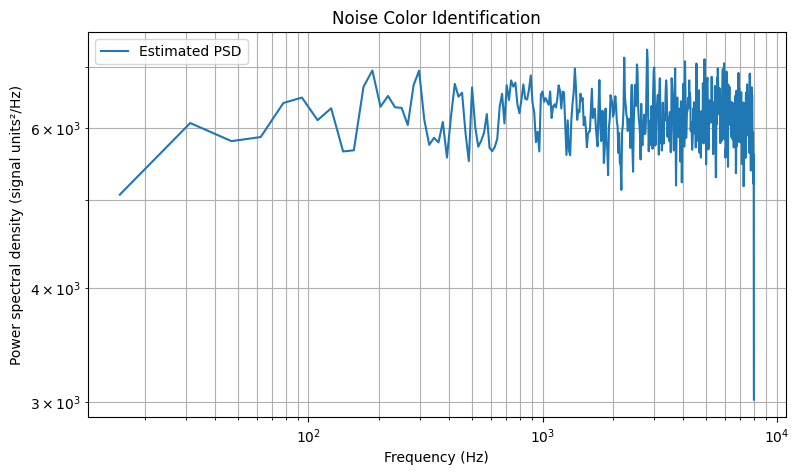

Estimated log-log slope: -1.002
Estimated noise color: Pink-like


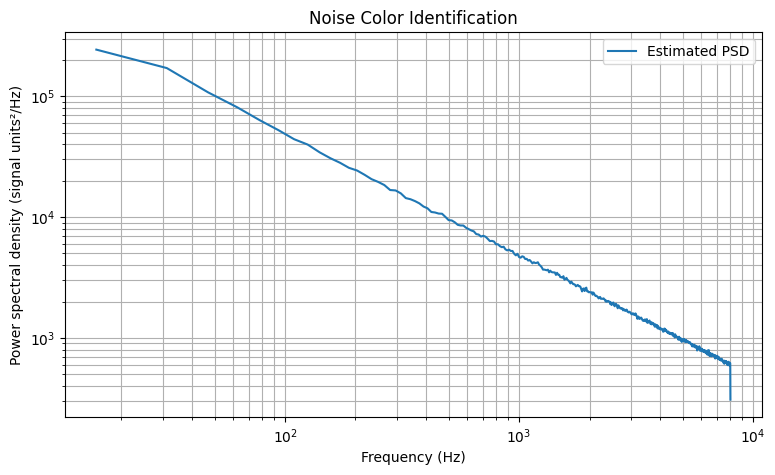

Estimated log-log slope: -0.374
Estimated noise color: Mixed or other noise color


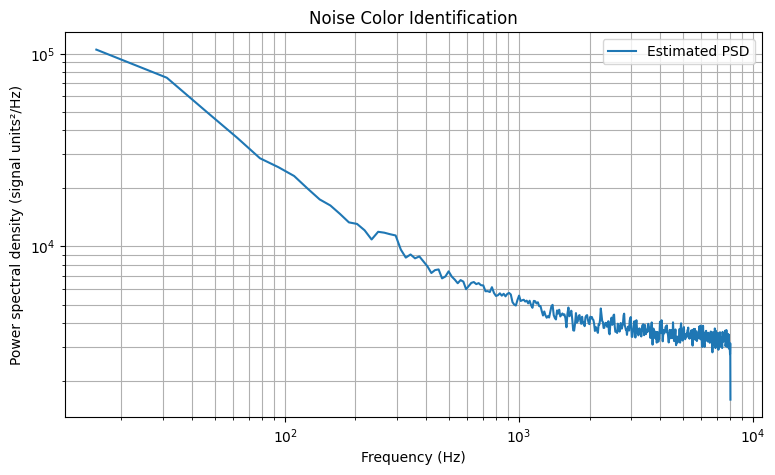

(-0.3735125862436486, 'Mixed or other noise color')

In [59]:
# estimate the noise color for each of the three signals using the Welch PSD
estimate_noise_color(f1_w, psd1_w)
estimate_noise_color(f2_w, psd2_w)
estimate_noise_color(f3_w, psd3_w)